In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def sma_crossover_signals(price, fast=10, slow=30):
    df = pd.DataFrame({"price": price})

    df["fast_ma"] = df["price"].rolling(fast).mean()
    df["slow_ma"] = df["price"].rolling(slow).mean()

    df["signal"] = 0
    df.loc[df["fast_ma"] > df["slow_ma"], "signal"] = 1
    df.loc[df["fast_ma"] < df["slow_ma"], "signal"] = -1

    # Shift signals forward one period to avoid look-ahead bias
    df["position"] = df["signal"].shift(1).fillna(0)

    return df


In [ ]:
def apply_commissions(df, commission_bps=1):
  df = df.copy()
  df["trades"] = df["position"].diff().abs().fillna(0)
  commission_rate = commission_bps / 10_000
  df["commission_cost"] = df["trades"] * commission_rate
  return df


In [ ]:
def apply_financing_cost(df, annual_rate=0.05, periods_per_year=252):
  df = df.copy()
  daily_rate = annual_rate / periods_per_year
  df["exposure"] = df["position"].abs()
  df["financing_cost"] = df["exposure"] * daily_rate
  return df


In [ ]:
def apply_borrow_cost(df, borrow_bps=10):
  df = df.copy()
  borrow_rate = borrow_bps / 10_000
  df["short_exposure"] = (df["position"] < 0).astype(int)
  df["borrow_cost"] = df["short_exposure"] * borrow_rate
  return df


In [ ]:
# Download data
df = yf.download("SPY", start="2015-01-01", auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

# Run the trading algo
df = sma_crossover_signals(df["Close"])

[*********************100%***********************]  1 of 1 completed


In [ ]:
df = apply_commissions(df, commission_bps=1)

df = apply_financing_cost(
    df,
    annual_rate=0.05,
    periods_per_year=252
)

df = apply_borrow_cost(
    df,
    borrow_bps=10
)

df["total_cost"] = (
    df["commission_cost"]
    + df["financing_cost"]
    + df["borrow_cost"]
)

df["returns"] = df["price"].pct_change()

df["strategy_returns"] = (
    df["position"] * df["returns"]
    - df["total_cost"]
)

df["equity_curve"] = (
    1 + df["strategy_returns"]
).cumprod()

df["raw_equity_curve"] = (
    1 + df["position"] * df["returns"]
).cumprod()

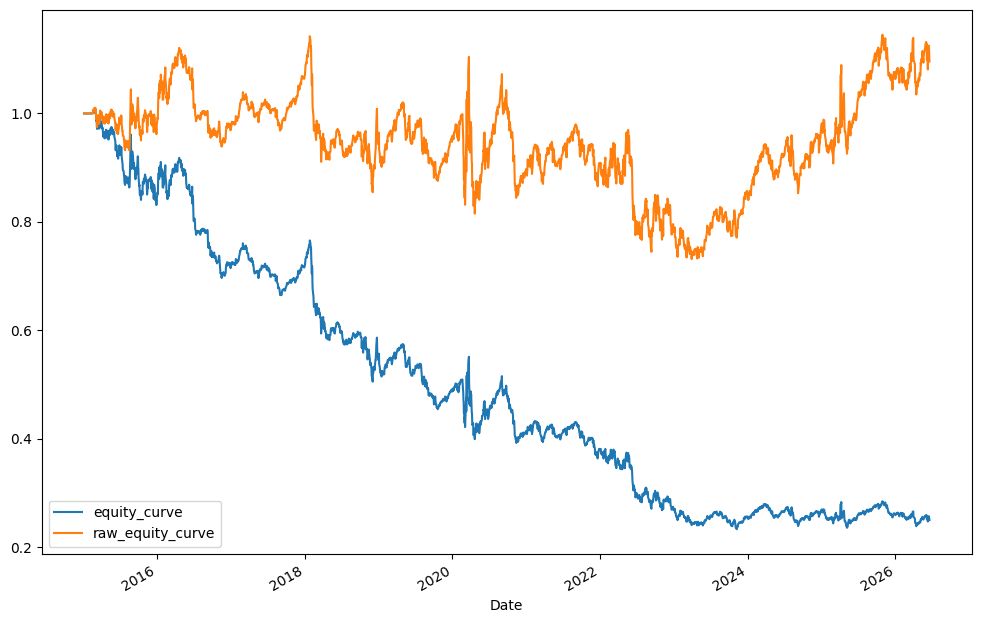

In [ ]:
# Plot results
df[["equity_curve", "raw_equity_curve"]].plot(figsize=(12, 8));